# 7 · Efficient learning and tracking

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → **7 · Efficient learning and tracking** → [8 · Real hardware](08_real_hardware.ipynb)

**Question.** The calibrators of notebooks 3–5 search with an optimiser and spend millions of shots. What is the
most shot-efficient way to learn the correction? And when the channel drifts, how few shots per step keep the
correction right?

The channels are those of notebook 5 (a rotation and an incoherent family on each leg), random draws.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import time
import numpy as np
import matplotlib.pyplot as plt
from telecorr import tracking as Tr, calibrate as K, channels as C
from telecorr.ceiling import ceiling
from telecorr.reference import simulation, number
from telecorr.plotting import use_style, CONDITION, SLOTS, INK_2
from telecorr.report import md_table, show
use_style()

## The model: TOMO-9, process tomography in nine circuits

Put a *known* rotation S in the correction box and send the three probes. Each probe circuit then measures one
linear function of the leg's transfer matrix (notebook 5): λ_a = Σ_c S_ac T_ca. Three settings,
S ∈ {I, C, C²} with C the 120° rotation about (1, 1, 1), make the nine circuits read **every entry of T exactly
once** (Theorem T7.2). T then follows by simple inversion, and the correction is its Procrustes rotation
(notebook 5): no optimiser and no search.

With S shots in total, the gap to the ceiling falls as **c / S** (Proposition P7.5): the estimate's error is
first order, but the loss in fidelity is second order in it. The constant c measures a method's efficiency.

In [2]:
T0 = Tr.drift_scenarios(np.random.default_rng(102), 200, steps=1, **{k: v for k, v in Tr.SCENARIOS["slow"].items()})
rows, pts = [], []
for N in (100, 300, 1000, 3000, 10000, 30000):
    r = Tr.summary(Tr.run_tomo9(np.repeat(T0, 2, 0), N, seed=N))        # 200 random channels, 2 independent rounds
    gap = r["mean_gap"]; S = 9 * N
    rows.append((N, S, f"{gap:.2e}", f"{gap * S:.2f}")); pts.append((S, gap))
show(md_table(rows, ["shots per circuit N", "total shots S = 9 N", "mean gap to the ceiling", "gap × S"]))

| shots per circuit N | total shots S = 9 N | mean gap to the ceiling | gap × S |
|---|---|---|---|
| 100 | 900 | 5.15e-03 | 4.64 |
| 300 | 2700 | 1.78e-03 | 4.80 |
| 1000 | 9000 | 5.59e-04 | 5.03 |
| 3000 | 27000 | 1.78e-04 | 4.81 |
| 10000 | 90000 | 5.21e-05 | 4.69 |
| 30000 | 270000 | 1.84e-05 | 4.97 |

For comparison, the Rotosolve calibrator of notebook 5 on a few of the same channels:

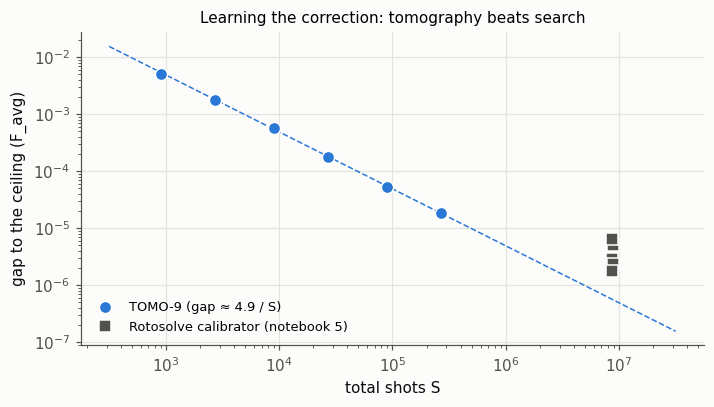

TOMO-9: gap × shots ≈ **4.87** (the study: ≈ 4.9). Rotosolve: gap × shots = 45, 56, 20, 25, 21, 15 on the same channels.

In [3]:
roto = []
for i in range(6):
    T = {2: T0[0, i, 0], 3: T0[0, i, 1]}
    cal = K.RelativeAutoCalibrator(K.ProbeSampler(T, np.random.default_rng(i)), seed=i)
    info = cal.recalibrate()
    roto.append((info["shots"], ceiling(T)[1] - K.scores(cal.params, T, [])["F_avg"]))
c9 = np.mean([g * S for S, g in pts[2:]])
fig, ax = plt.subplots(figsize=(6.6, 3.8))
SS = np.logspace(2.5, 7.5, 50)
ax.loglog(SS, c9 / SS, color=CONDITION["learned from counts"], lw=1, ls="--")
ax.loglog(*zip(*pts), "o", color=CONDITION["learned from counts"], mec="white", ms=8, label=f"TOMO-9 (gap ≈ {c9:.1f} / S)")
ax.loglog([s for s, _ in roto], [max(g, 1e-9) for _, g in roto], "s", color=INK_2, mec="white", ms=8,
          label="Rotosolve calibrator (notebook 5)")
ax.set_xlabel("total shots S"); ax.set_ylabel("gap to the ceiling (F_avg)")
ax.set_title("Learning the correction: tomography beats search", fontsize=10)
ax.legend(fontsize=8.5, loc="lower left"); plt.tight_layout(); plt.show()
show(f"TOMO-9: gap × shots ≈ **{c9:.2f}** (the study: ≈ {number('n0035')}). Rotosolve: gap × shots = "
     + ", ".join(f"{g * s:.0f}" for s, g in roto) + " on the same channels.")

## Tracking a drifting channel: Kalman memory and the ABC rule

When the channel drifts slowly, the previous estimate of T is still informative. A **Kalman filter** keeps a
Gaussian belief about each leg's T and updates it with every probe round. The drift enters as process noise
along the rotation directions of T, with a drift rate learned from the data. A large innovation signals a jump
and restarts the filter from a fresh TOMO-9 (Proposition P7.8).

**ABC** decides how much to measure at each step. Among 1, 2 or 3 rounds of the most informative settings, or a
fresh TOMO-9, each with N shots per circuit, it takes the *cheapest* option whose predicted gap is below a target.
Information balance predicts the saving: the gain over TOMO-9 every step is 1 + (target loss)/(one-step drift loss),
large for slow drift (Proposition P7.9).

Below: the study's "slow" drift scenario, 200 episodes of 60 steps, with the study's random seeds. ABC is compared
with TOMO-9 at every step.

In [4]:
t0 = time.time()
Ts = Tr.drift_scenarios(np.random.default_rng(102), 200, **Tr.SCENARIOS["slow"])
abc = {tg: Tr.summary(Tr.run_abc(Ts, tg, seed=111)) for tg in (3e-4, 1e-4)}
t9 = {N: Tr.summary(Tr.run_tomo9(Ts, N, seed=121)) for N in (300, 1000, 3000, 10000)}
saved = simulation("7f_tracking.json")["slow"]
rows = [(f"ABC, target {tg:g}", r["shots_per_step"], f"{r['mean_gap']:.3e}", f"{saved[f'ABC target {tg:g}']['mean_gap']:.3e}") for tg, r in abc.items()]
rows += [(f"TOMO-9 every step, N = {N}", r["shots_per_step"], f"{r['mean_gap']:.3e}", f"{saved[f'TOMO-9 every step, N = {N}']['mean_gap']:.3e}")
         for N, r in t9.items()]
show(md_table(rows, ["strategy", "shots per step", "mean gap", "the study's mean gap"], 1))
c_abc = np.mean([r["constant"] for r in abc.values()]); c_t9 = np.mean([r["constant"] for r in t9.values()])
show(f"Gain of ABC over TOMO-9 every step (ratio of gap × shots): **{c_t9 / c_abc:.1f}×** (the study: {number('s7gains')['slow'].split(' / ')[0]}). "
     f"Run time {time.time() - t0:.0f} s.")

| strategy | shots per step | mean gap | the study's mean gap |
|---|---|---|---|
| ABC, target 0.0003 | 4157.8 | 2.440e-04 | 2.440e-04 |
| ABC, target 0.0001 | 21926.7 | 8.690e-05 | 8.690e-05 |
| TOMO-9 every step, N = 300 | 2700.0 | 1.771e-03 | 1.771e-03 |
| TOMO-9 every step, N = 1000 | 9000.0 | 5.319e-04 | 5.319e-04 |
| TOMO-9 every step, N = 3000 | 27000.0 | 1.773e-04 | 1.773e-04 |
| TOMO-9 every step, N = 10000 | 90000.0 | 5.286e-05 | 5.286e-05 |

Gain of ABC over TOMO-9 every step (ratio of gap × shots): **3.3×** (the study: 3.3×). Run time 62 s.

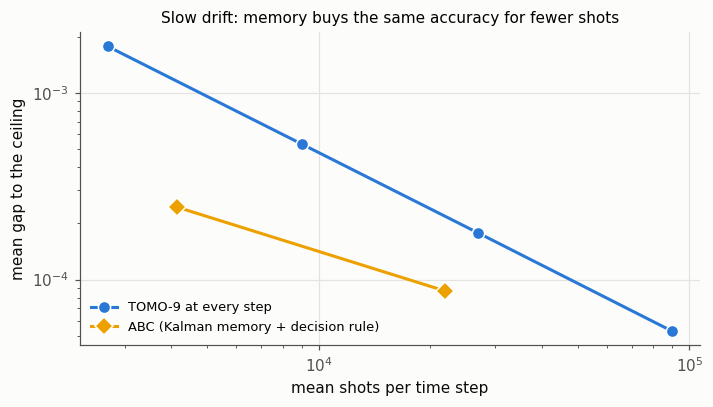

In [5]:
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.loglog([r["shots_per_step"] for r in t9.values()], [r["mean_gap"] for r in t9.values()], "o-", color=CONDITION["learned from counts"],
          mec="white", ms=8, label="TOMO-9 at every step")
ax.loglog([r["shots_per_step"] for r in abc.values()], [r["mean_gap"] for r in abc.values()], "D-", color=CONDITION["ceiling"],
          mec="white", ms=8, label="ABC (Kalman memory + decision rule)")
ax.set_xlabel("mean shots per time step"); ax.set_ylabel("mean gap to the ceiling")
ax.set_title("Slow drift: memory buys the same accuracy for fewer shots", fontsize=10)
ax.legend(fontsize=8.5, loc="lower left"); plt.tight_layout(); plt.show()

## Across drift speeds, and the reinforcement-learning agents

The study ran the same comparison for six drift scenarios, and it trained reinforcement-learning (RL) agents for
the same tasks: one-shot correctors, sequential agents, an "experiment designer" that picks the probe settings,
and an RL controller that takes ABC's decisions. The RL agents are **not retrained here** (training takes hours and
needs the optional RL libraries); their saved results are shown for comparison.

In [6]:
tr = simulation("7f_tracking.json"); gains = number("s7gains")
PLAIN = {"fast (Stage 5 rates)": "fast (the drift of notebook 4's timeline)", "ARB, medium": "medium, arbitrary channels",
         "Stage 5 exact sequence": "the timeline of notebook 4, with changing incoherent noise M"}
def const(res, prefix):
    return np.mean([v["mean_gap"] * v["shots_per_step"] for k, v in res.items() if k.startswith(prefix)])
rows = []
for name, res in tr.items():
    if name.startswith("_"):
        continue
    cl, rl = gains[name].split(" / ")
    rows.append((PLAIN.get(name, name), const(res, "TOMO-9 every step"), const(res, "RL designer B every step"), cl, rl))
show(md_table(rows, ["drift scenario (the study's saved results)", "TOMO-9 every step: gap × shots", "RL experiment designer: gap × shots",
                     "gain of ABC, classical rule", "gain of ABC, RL controller"], 2))

| drift scenario (the study's saved results) | TOMO-9 every step: gap × shots | RL experiment designer: gap × shots | gain of ABC, classical rule | gain of ABC, RL controller |
|---|---|---|---|---|
| very slow | 4.76 | 5.04 | 6.1× | 5.7× |
| slow | 4.78 | 4.98 | 3.3× | 2.9× |
| medium | 4.80 | 5.02 | 1.4× | 1.4× |
| fast (the drift of notebook 4's timeline) | 4.81 | 5.04 | 0.7× | 0.9× |
| medium, arbitrary channels | 5.28 | 5.71 | 1.2× | 1.3× |
| the timeline of notebook 4, with changing incoherent noise M | 4.49 | 5.10 | 0.9× | 1.0× |

The RL experiment designer reaches about the efficiency of TOMO-9 but not better, and the RL controller of ABC
reaches about the same gains as the classical decision rule. Learning reproduced what the analysis derives; it did
not exceed it.

## What it means

* **Tomography beats search.** TOMO-9 learns the correction in nine circuits with no optimiser, with a gap of
  about 5 / S: three to ten times fewer shots than the Rotosolve calibrator needs for the same accuracy.
* **Memory pays when the channel drifts slowly.** The Kalman tracker with the ABC rule needs several times fewer
  shots than repeating TOMO-9 at every step. The gain shrinks as the drift speeds up, as information balance
  predicts. For the fastest drift it falls below 1, and a fresh TOMO-9 at every step is the better choice.
* Reinforcement learning, trained on the same problems, matched these classical methods but did not beat them.

**Next (notebook 8):** TOMO-9's efficiency (nine circuits, closed-form correction) is what makes the experiment on a
real quantum computer affordable. Does it work there?